## Лабораторная работа №3. Кластеризация

**Датасет:** Student Depression Detection (Выявление депрессии у студентов)

**Цель работы:** изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

---

### Постановка задачи

1. Загрузить датасет. Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.


In [39]:
import pandas as pd
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import skew, kurtosis, normaltest
import warnings
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import beta
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, 
    calinski_harabasz_score, 
    davies_bouldin_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    v_measure_score,
    homogeneity_score,
    completeness_score
)

from kneed import KneeLocator
from scipy.spatial.distance import cdist

Подключаем необходимые для работы библиотеки.

In [40]:
df = pd.read_excel('data.xlsx', engine='openpyxl')
df.columns = df.columns.str.strip()

df = df.head(4000).reset_index(drop=True)

print("Размер датасета (строк, столбцов):", df.shape)
df.head()

Размер датасета (строк, столбцов): (4000, 12)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Yes


### Описание датасета

Датасет **Student Depression Detection**  содержит **11 переменных** одна из которых целевая переменная - **`Depression`**. 

| Переменная | Описание | Тип |
| --- | --- | --- |
| `Gender` | пол студента | категориальная номинальная независимая |
| `Age` | 	возраст студента | числовая дискретная независимая |
| `Family_background` | положение семьи | категориальная номинальная независимая |
| `Relationship_status` | наличие романтических отношений | категориальная номинальная независимая |
| `Marital_status` | семейное положение | категориальная номинальная независимая |
| `Current_semester` | текущий семестр обучения | категориальная номинальная независимая |
| `CGPA` | средний академический балл | числовая непрерывная независимая |
| `friend_circle` | наличие и размер круга общения | категориальная номинальная независимая |
| `Cost_without_study` | расходы, не связанные с учёбой | числовая непрерывная независимая |
| `Health_condition` | состояние здоровья | категориальная номинальная независимая |
| **`Depression`** | **признак депрессии: Yes — есть, No — нет** | **категориальная номинальная зависимая** |

In [41]:
df.info()
print()
print("Пропущенных значений всего:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())
df.describe().T.round(3)

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4000 non-null   str    
 1   Age                  4000 non-null   int64  
 2   Family_background    4000 non-null   str    
 3   Relationship_status  4000 non-null   str    
 4   Marital_status       4000 non-null   str    
 5   Living_style         4000 non-null   str    
 6   Current_semester     4000 non-null   int64  
 7   CGPA                 4000 non-null   float64
 8   friend_circle        4000 non-null   str    
 9   Health_condition     4000 non-null   str    
 10  Cost_without_study   4000 non-null   int64  
 11  Depression           4000 non-null   str    
dtypes: float64(1), int64(3), str(8)
memory usage: 375.1 KB

Пропущенных значений всего: 0
Полных дубликатов строк: 3


,count,mean,std,min,25%,50%,75%,max
Age,4000.0,22.608,2.033,17.00,21.00,23.00,24.0,28.0
Current_semester,4000.0,5.321,2.583,0.00,3.00,5.00,7.0,13.0
CGPA,4000.0,3.411,0.385,2.25,3.16,3.49,3.7,4.0
Cost_without_study,4000.0,10787.294,6458.860,0.00,6000.00,9000.00,14867.0,32000.0


In [42]:
df.describe(include='str').T.round(3)

,count,unique,top,freq
Gender,4000,2,Female,2222
Family_background,4000,3,Middle class,2386
Relationship_status,4000,3,Single,2525
Marital_status,4000,3,Unmarried,3299
Living_style,4000,2,Bachelor,2148
friend_circle,4000,2,Yes,2900
Health_condition,4000,4,Normal,1615
Depression,4000,2,No,2940


             Параметр  Асимметрия  Эксцесс
0                 Age      0.0740  -0.1809
1    Current_semester      0.3687  -0.4919
2                CGPA     -0.6139  -0.2707
3  Cost_without_study      0.9293   0.2945

Проверка нормальности (тест Д’Агостино-Пирсона):
Age: статистика=9.9933, p-значение=0.0068 → отличается от нормального

Current_semester: статистика=157.7700, p-значение=0.0000 → отличается от нормального

CGPA: статистика=231.4475, p-значение=0.0000 → отличается от нормального

Cost_without_study: статистика=436.7734, p-значение=0.0000 → отличается от нормального

Число бинов по формуле Стерджеса: 12



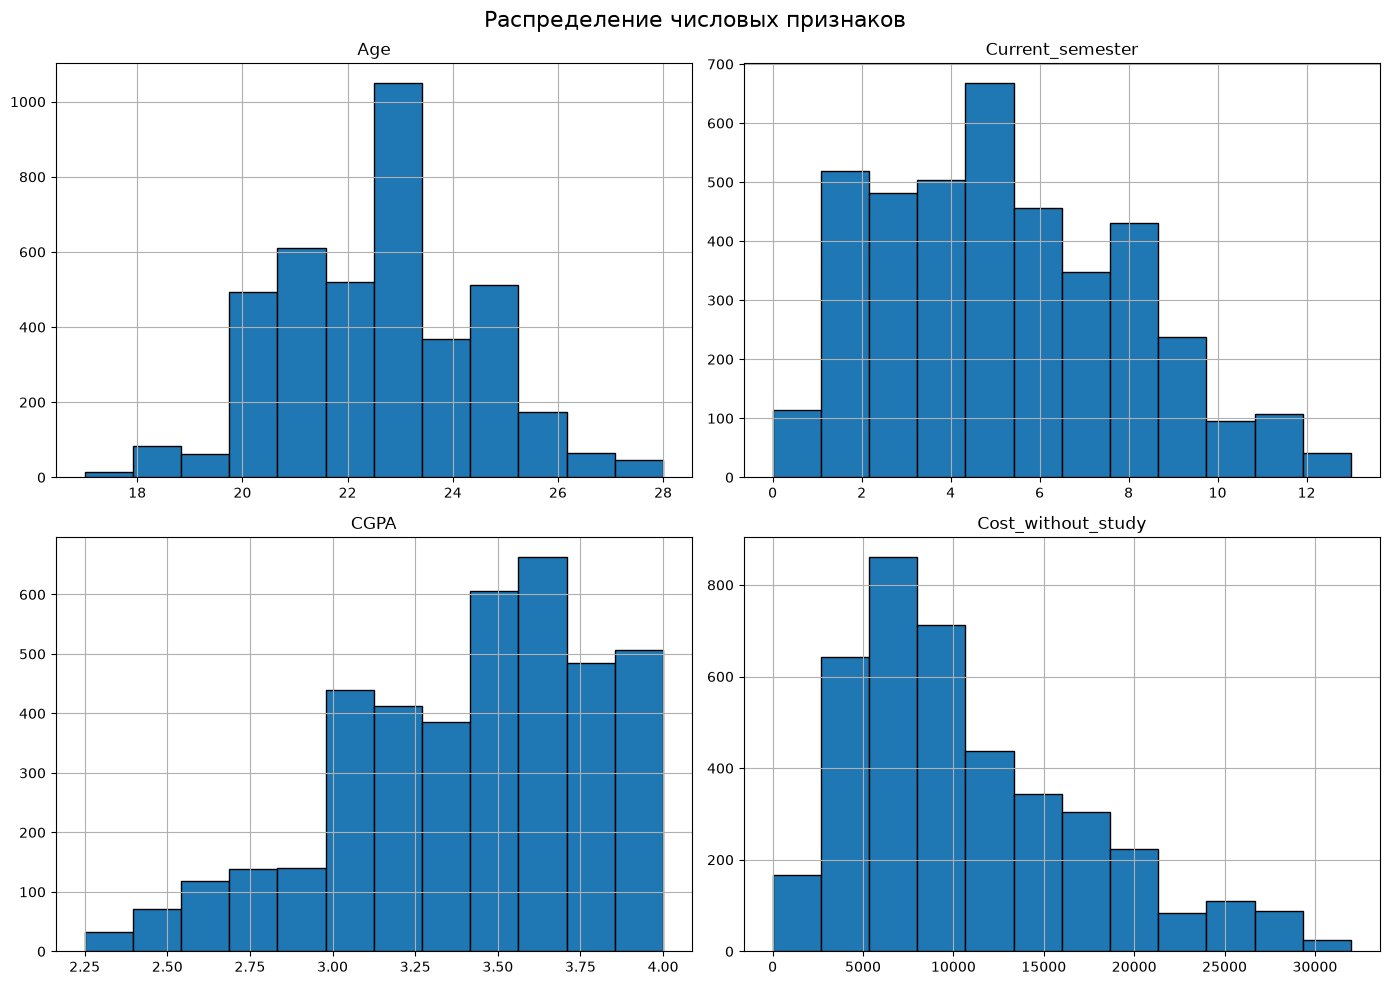

CGPA: найдено 20 выбросов (границы: 2.35 – 4.51)
Cost_without_study: найдено 64 выбросов (границы: -7300.50 – 28167.50)


{'Age': 0, 'Current_semester': 0, 'CGPA': 20, 'Cost_without_study': 64}

In [43]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

features_only = [c for c in numeric_cols if c != TARGET] \
                if 'TARGET' in globals() else numeric_cols


data = {'Параметр': [], 'Асимметрия': [], 'Эксцесс': []}

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for col in features_only:
        vals = df[col].dropna()
        data['Параметр'].append(col)
        data['Асимметрия'].append(skew(vals))
        data['Эксцесс'].append(kurtosis(vals))

summary_df = pd.DataFrame(data)
print(summary_df.round(4))


print("\nПроверка нормальности (тест Д’Агостино-Пирсона):")

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    for col in features_only:
        vals = df[col].dropna()
        stat, p = normaltest(vals)
        verdict = ("близко к нормальному"
                   if p > 0.05 else "отличается от нормального")
        print(f"{col}: статистика={stat:.4f}, "
              f"p-значение={p:.4f} → {verdict}\n")


count_of_bins = int(1 + 3.322 * math.log10(df.shape[0]))
print(f"Число бинов по формуле Стерджеса: {count_of_bins}\n")

df[features_only].hist(
    bins=count_of_bins,
    figsize=(14, 10),
    edgecolor="black"
)
plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

def find_outliers_iqr(df, cols=None):
    if cols is None:
        cols = df.select_dtypes(include=[np.number]).columns
    
    outliers_dict = {}
    for col in cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
    
        outlier_indices = df[(df[col] < lower_bound) | (df[col] > upper_bound)].index
        outliers_dict[col] = len(outlier_indices)
        
        if len(outlier_indices) > 0:
            print(f"{col}: найдено {len(outlier_indices)} выбросов (границы: {lower_bound:.2f} – {upper_bound:.2f})")
    
    return outliers_dict



find_outliers_iqr(df, numeric_cols)


In [44]:
TARGET = 'Depression'

X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy().map({'Yes': 1, 'No': 0})

cat_cols = X.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'str', 'category']).columns.tolist()

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True, dtype=int)

df_encoded = X_encoded.copy()
corr_matrix = df_encoded.corr(method='spearman').abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)


threshold = 0.7

strong_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'abs_corr'})
    .query('abs_corr >= @threshold')
    .sort_values('abs_corr', ascending=False)
    .reset_index(drop=True)
)

print(f"\nПар признаков с |corr| >= {threshold}: {len(strong_pairs)}\n")
print(strong_pairs.to_string(index=False))

X_encoded.drop(columns='Relationship_status_In a Relationship',inplace=True)

df_encoded = X_encoded.copy()
corr_matrix = df_encoded.corr(method='spearman').abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.7

strong_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'feature_1', 'level_1': 'feature_2', 0: 'abs_corr'})
    .query('abs_corr >= @threshold')
    .sort_values('abs_corr', ascending=False)
    .reset_index(drop=True)
)
print(f"\nПар признаков с |corr| >= {threshold}: {len(strong_pairs)}\n")



Пар признаков с |corr| >= 0.7: 1

                            feature_1                  feature_2  abs_corr
Relationship_status_In a Relationship Relationship_status_Single  0.909942

Пар признаков с |corr| >= 0.7: 0



### Корреляционный и дескриптивный анализ

**Дескриптивный анализ** показал, что признаки имеют разный масштаб (например, `Cost_without_study` достигает тысяч, `СGPA` — максимально достигает четырех). 

Тест Д’Агостино-Пирсона показал, что **распределения не соответствуют нормальному**. 

В признаке Cost_without_study было выявлено **64 выброса (1.6% выборки)**, что отражает студентов с аномально высокими расходами, не связанными с учёбой.  В признаке CGPA было выявлено **20 выбросов (0.5% выборки)**.

Эти выбросы были оставлены в выборке, так как их количество статистически незначительно (в сумме менее 2% данных) и они не оказывают существенного влияния на обучение модели.

Все категориальные признаки были закодированы с помощью **One-Hot-Encoding**. Целевая переменная была закодирована: No - 0 Yes - 1.

**Корреляционный анализ** показал, что в датасете имеется 1 пара признаков с сильной корреляцией - Relationship_status_In a Relationship и Relationship_status_Single.  

Relationship_status_In a Relationship (corr = 0.91 с Relationship_status_Single) **был удалён для устранения мультиколлинеарности**. 

In [45]:
def significance_by_variability_correlation(
    df,
    exclude_cols=None,
    pc1_weight=0.5,
):
    X = df.copy()
    if exclude_cols:
        X = X.drop(columns=[c for c in exclude_cols if c in X.columns])

    X = X.select_dtypes(include=[np.number])
    features = X.columns.tolist()

    raw_stats = pd.DataFrame({
        'raw_mean': X.mean(),
        'raw_std': X.std(),
        'raw_cv': X.std() / (X.mean().abs() + 1e-12),
        'raw_max': X.max(),
        'zero_share': (X == 0).mean(),
        'nunique': X.nunique(),
    })

    Xt = X.copy()

    Xs = pd.DataFrame(
        StandardScaler().fit_transform(Xt),
        columns=features, index=Xt.index,
    )


    var_std = Xs.std()
    var_iqr = Xs.quantile(0.75) - Xs.quantile(0.25)

    def norm01(s):
        rng = s.max() - s.min()
        return (s - s.min()) / rng if rng > 0 else pd.Series(0.0, index=s.index)

    var_score = (norm01(var_std) + norm01(var_iqr)) / 2

  
    corr_abs = Xs.corr().abs()
    corr_arr = corr_abs.to_numpy(copy=True)   
    np.fill_diagonal(corr_arr, 0.0)
    corr_abs = pd.DataFrame(corr_arr, index=corr_abs.index, columns=corr_abs.columns)

    mean_corr_other = corr_abs.mean(axis=1)

    pc1 = PCA(n_components=1, random_state=42).fit_transform(Xs)[:, 0]
    pc1_corr = Xs.apply(lambda col: np.corrcoef(col, pc1)[0, 1]).abs()

    corr_score = (
        norm01(pc1_corr) * pc1_weight
        + norm01(mean_corr_other) * (1 - pc1_weight)
    )

   
    final_score = (var_score + corr_score) / 2

    result = pd.concat([
        raw_stats,
        pd.DataFrame({
            'var_score': var_score,
            'mean_corr_other': mean_corr_other,
            'pc1_corr': pc1_corr,
            'corr_score': corr_score,
            'final_score': final_score,
        })
    ], axis=1).sort_values('final_score', ascending=False)

    result['rank'] = range(1, len(result) + 1)
    return result


def select_by_criteria(result, top_k=None, min_score=None):
    if top_k is not None:
        return result.head(top_k).index.tolist()
    if min_score is not None:
        return result[result['final_score'] >= min_score].index.tolist()
    raise ValueError("Укажите top_k или min_score")



res = significance_by_variability_correlation(
    X_encoded,                     
    exclude_cols=None,              
    pc1_weight=0.5,
)

print("Значимость признаков\n")
display(res[['rank', 'var_score', 'corr_score', 'final_score']])

Значимость признаков



,rank,var_score,corr_score,final_score
Relationship_status_Single,1,0.705703,0.951745,0.828724
Gender_Male,2,0.692457,0.943495,0.817976
Age,3,0.574431,0.744876,0.659654
Living_style_Family,4,0.440932,0.874009,0.657470
Family_background_Middle class,5,0.698148,0.462012,0.580080
Family_background_Rich class,6,0.500000,0.598295,0.549147
Current_semester,7,0.590536,0.442536,0.516536
Marital_status_Unmarried,8,0.000000,1.000000,0.500000
Cost_without_study,9,0.551873,0.416114,0.483993
friend_circle_Yes,10,0.742395,0.125785,0.434090


### Оценка значимости признаков

Оценка значимости проводилась по двум критериям: вариативность и коррелированность . 

Признаки с высокой вариативностью и заметной связью с общей структурой данных получали высокий балл.

**var_score** — оценка вариативности признака. Рассчитывается как нормированное среднее стандартного отклонения и межквартильного размаха (IQR) после стандартизации данных. Чем выше этот показатель, тем больше информации о различиях между студентами несет признак.

**corr_score** — оценка информационной ценности признака на основе его корреляционных связей. Она учитывает, насколько сильно признак связан с главной осью вариации данных и насколько он в среднем связан с другими признаками. Высокое значение указывает на то, что признак отражает общую структуру данных.

В ходе анализа было принято решение **оставить все 15 отобранных признаков**, включая те, что имеют низкий итоговый балл значимости. Признаки могут быть важными для выделения специфических подгрупп студентов

In [46]:


def hopkins_statistic(X, n_samples=None, random_state=42):
    X = np.asarray(X, dtype=float)
    n, d = X.shape

    if n_samples is None:
        n_samples = max(10, min(n // 10, n // 2))
    m = n_samples

    rng = np.random.default_rng(random_state)

    nn_real = NearestNeighbors(n_neighbors=2).fit(X)
    dist_real, _ = nn_real.kneighbors(X)
    w = dist_real[:, 1]                      
    w_sample = rng.choice(w, size=m, replace=False)

    mins = X.min(axis=0)
    maxs = X.max(axis=0)
    U = rng.uniform(mins, maxs, size=(m, d))

    nn_U = NearestNeighbors(n_neighbors=1).fit(X)
    dist_U, _ = nn_U.kneighbors(U)
    u = dist_U[:, 0]

    H = u.sum() / (u.sum() + w_sample.sum())
    p_value = 1 - beta.cdf(H, m, m) if H > 0.5 else beta.cdf(H, m, m)

    return H, p_value

def check_cluster_tendency(X, n_runs=20, random_state=42):
    Hs, ps = [], []
    for i in range(n_runs):
        H, p = hopkins_statistic(X, random_state=random_state + i)
        Hs.append(H)
        ps.append(p)
    return {
        'H_mean': float(np.mean(Hs)),
        'H_std': float(np.std(Hs)),
        'p_value_mean': float(np.mean(ps)),
        'n_runs': n_runs,
    }

X_scaled = StandardScaler().fit_transform(X_encoded)

result = check_cluster_tendency(X_scaled, n_runs=20, random_state=42)
print(result)

{'H_mean': 0.830345992613213, 'H_std': 0.004817721443653783, 'p_value_mean': 0.0, 'n_runs': 20}


### Проверка условий применения кластеризации

Для проверки склонности к кластеризации в наборе данных был **применена статистика Хопкинса**. 

**H-mean = 0.83**, значит в данных присутствует сильная кластерная тенденция — кластеризовать имеет смысл.

**Анализ выбросов** показал, что экстремальные значения в датасете не являются грубыми ошибками, а отражают естественный разброс характеристик студентов (например, более высокие расходы Cost_without_study или возрастные границы). Поэтому выбросы не удалялись как «шум», а нейтрализовались на этапе масштабирования.

**Стандартизация данных** была проведена с помощью метода StandardScaler. Для данного датасета он выбран потому, что распределения непрерывных признаков (Age, CGPA, Cost_without_study) не имеют экстремальных «тяжёлых хвостов» на порядки, а большинство остальных признаков являются бинарными (после One-Hot Encoding).


Данные готовы к применению кластеризации.

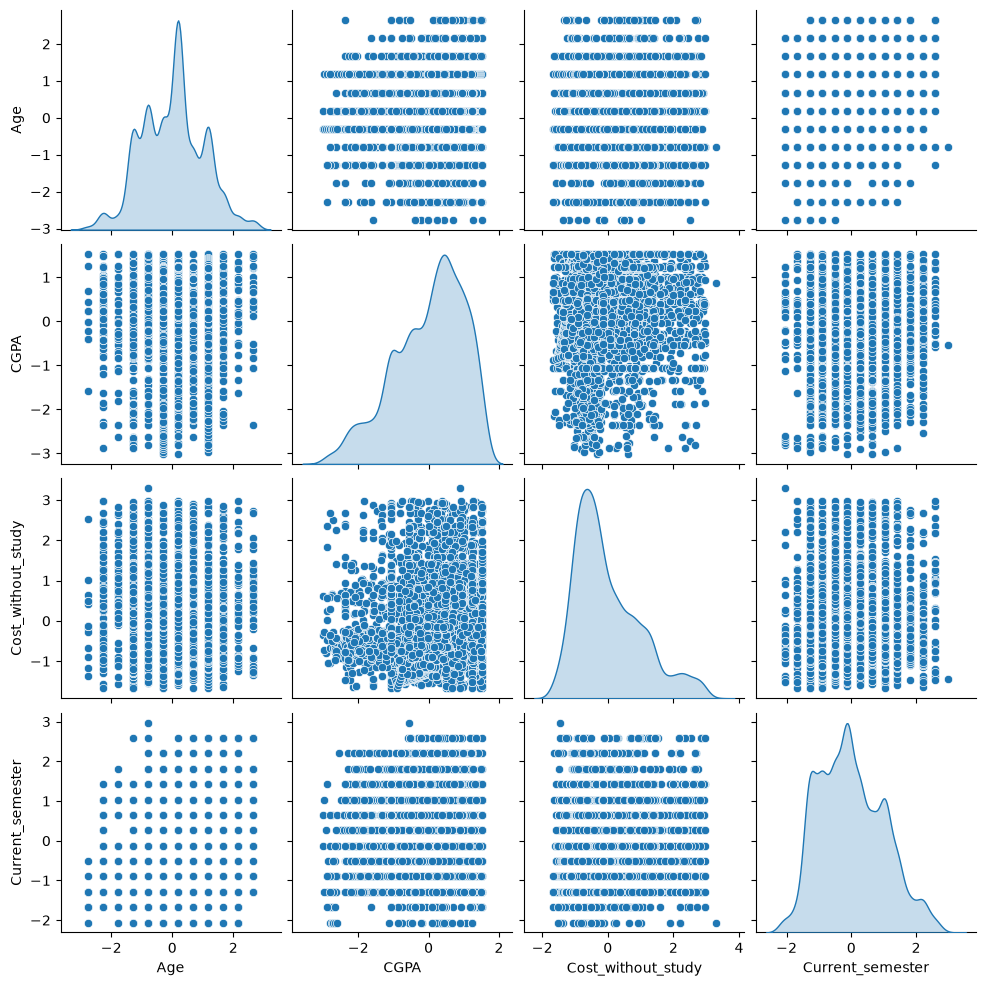

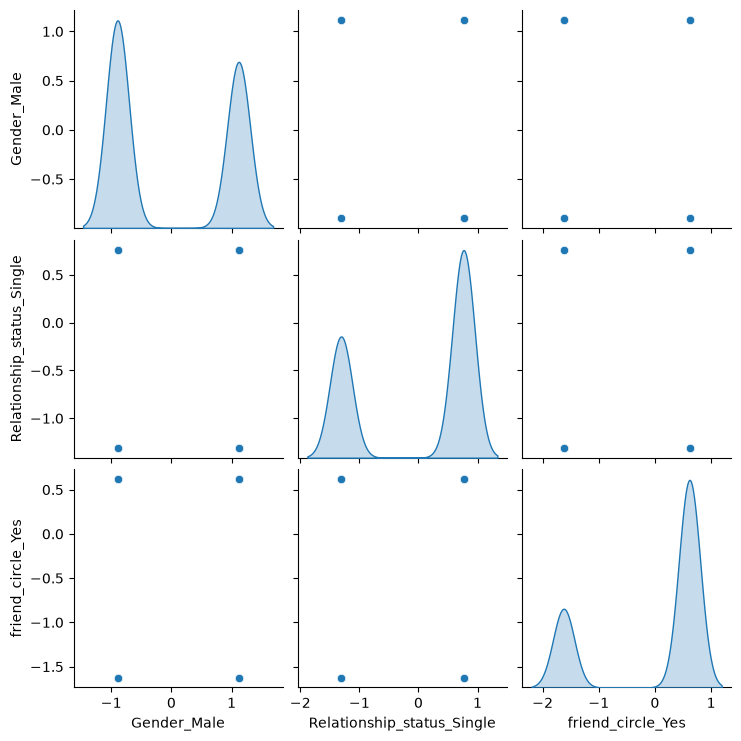

In [47]:

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_encoded), 
    columns=X_encoded.columns, 
    index=X_encoded.index
)

num_cols = ['Age', 'CGPA', 'Cost_without_study', 'Current_semester']
sns.pairplot(X_scaled[num_cols], diag_kind='kde')
plt.show()

bin_cols = ['Gender_Male', 'Relationship_status_Single', 'friend_circle_Yes']
sns.pairplot(X_scaled[bin_cols], diag_kind='kde') 
plt.show()

### Анализ матрицы диаграмм рассеивания

Матрица диаграмм рассеивания была построена по **7 из 15 признакам** - Age, CGPA, Cost_without_study, Current_semester, Gender_Male,Relationship_status_Single, friend_circle_Yes. Это наиболее интерпретируемые и значимые признаки для визуального анализа.

На представленной матрице визуально видно, что между числовыми признаками (Age, CGPA, Cost_without_study, Current_semester) отсутствуют четкие линейные зависимости — облака точек не образуют наклонных линий или узких эллипсов. Распределения на диагонали (KDE) показывают, что Age и Cost_without_study имеют скошенную форму с выраженными хвостами, в то время как CGPA представляет собой многовершинное (ступенчатое) распределение.

Особое внимание привлекает структура точечных графиков: CGPA и Current_semester образуют строгую сетку (точки выстраиваются в вертикальные и горизонтальные ряды), что является прямым следствием дискретной природы этих признаков. 

В целом, диаграмма подтверждает, что данные представляют собой единое облако с неоднородной плотностью, а не изолированные группы.

### Выбор методов кластеризации

Для кластеризации было выбрано 2 метода - **Иерархическая кластеризация и EM-алгоритм**.

**Иерархическая кластеризация выбрана**, поскольку диаграммы рассеивания показали наличие скошенных распределений и вытянутых, неоднородных облаков (особенно по признаку Cost_without_study), а также ступенчатых структур (CGPA). Ward минимизирует внутрикластерную дисперсию при слиянии, что позволяет корректно работать с такими вытянутыми и несбалансированными группами, не навязывая им жесткую сферическую форму. Кроме того, метод не требует задавать число кластеров заранее.
 
**EM-алгоритм (GMM)** был выбран, поскольку визуальный анализ подтвердил, что данные представляют собой единое плотное облако без резких границ, а признаки имеют разную плотность и дискретную структуру. GMM способен моделировать кластеры в виде эллипсов с разной плотностью (за счет полной ковариационной матрицы), что лучше подходит для таких размытых структур. Дополнительным преимуществом является то, что GMM предоставляет вероятностную оценку принадлежности каждого студента, позволяя выявить случаи, которые на диаграммах рассеивания находятся в зонах пересечения облаков.

### Применение Иерархической кластеризации

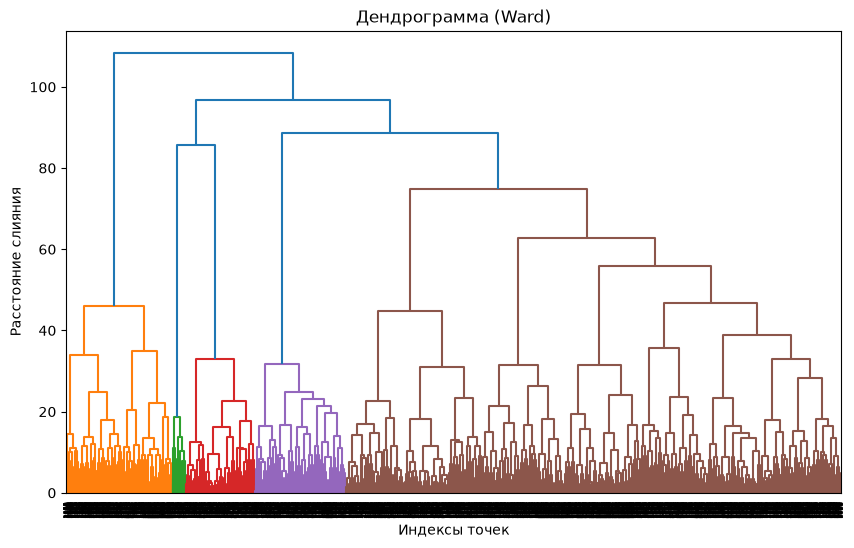

  n_components=2:  Silhouette=0.186
  n_components=3:  Silhouette=0.193
  n_components=4:  Silhouette=0.166
  n_components=5:  Silhouette=0.161
  n_components=6:  Silhouette=0.132
  n_components=7:  Silhouette=0.131
  n_components=8:  Silhouette=0.125


In [48]:
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 6))
dendrogram(Z)
plt.title('Дендрограмма (Ward)')
plt.xlabel('Индексы точек')
plt.ylabel('Расстояние слияния')
plt.show()

n_components_range = range(2,9)
for n in n_components_range:
    labels_ward = fcluster(Z, t=n, criterion='maxclust')

    
    if len(np.unique(labels_ward )) > 1:
        sil = silhouette_score(X_scaled, labels_ward)
    else:
        sil = -1

    
    print(f"  n_components={n}:  Silhouette={sil:.3f}")

#### Выбор количества кластеров

Выбор количества кластеров осуществлялся с помощью построения **дендрограммы**. Дополнительно использовался **метод Силуэта**.

На дендрограмме визуально выделяются три крупные ветви. Метод силуэта также показал лучшее значение при 3 кластерах. 

Для дальнейшей работы было выбрано **k = 3**

Unique cluster IDs: [1 2 3]
Sizes: [ 549  427 3024]


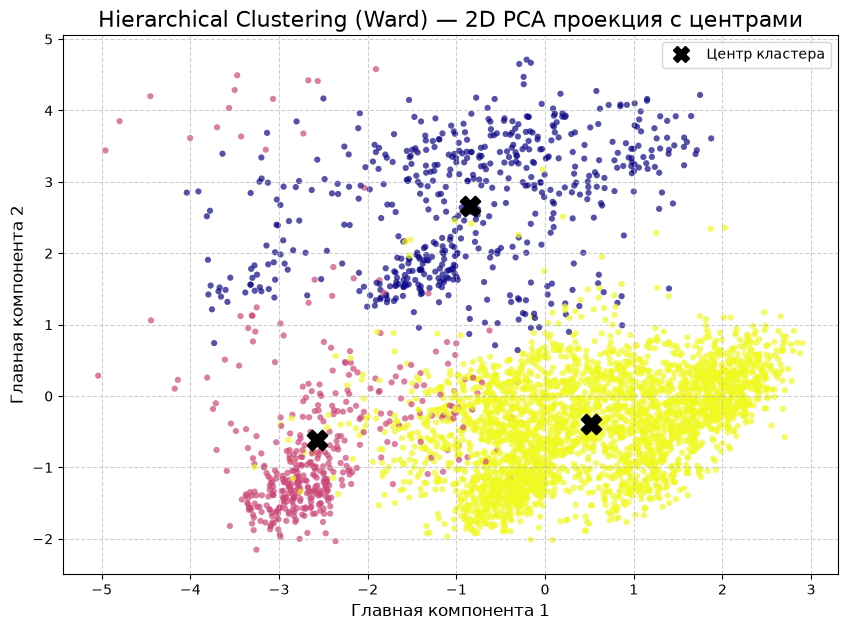

In [49]:
labels_ward = fcluster(Z, t=3, criterion='maxclust')

unique, counts = np.unique(labels_ward, return_counts=True)
print('Unique cluster IDs:', unique)
print('Sizes:', counts)


pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))


is_noise = labels_ward == -1
is_cluster = ~is_noise


if np.any(is_noise):
    plt.scatter(
        X_pca_2d[is_noise, 0], X_pca_2d[is_noise, 1], 
        c='lightgray', s=15, alpha=0.5, 
        label='Шум (-1)', edgecolors='none'
    )


scatter = plt.scatter(
    X_pca_2d[is_cluster, 0], X_pca_2d[is_cluster, 1], 
    c=labels_ward[is_cluster], cmap='plasma', s=20, alpha=0.7, edgecolors='none'
)


unique_clusters = [c for c in np.unique(labels_ward) if c != -1]

for cluster_id in unique_clusters:
    cluster_mask = labels_ward == cluster_id
    center_x = X_pca_2d[cluster_mask, 0].mean()
    center_y = X_pca_2d[cluster_mask, 1].mean()
    
    
    plt.scatter(
        center_x, center_y, 
        c='black', s=200, marker='X', edgecolors='black', linewidths=1.5,
        zorder=10 
    )
   


plt.title('Hierarchical Clustering (Ward) — 2D PCA проекция с центрами', fontsize=16)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)


legend_elements = [
    Line2D([0], [0], marker='X', color='w', label='Центр кластера', markerfacecolor='black', markeredgecolor='black', markersize=12)
]
if np.any(is_noise):
    legend_elements.append(Line2D([0], [0], marker='o', color='w', label='Шум', markerfacecolor='lightgray', markersize=8))

plt.legend(handles=legend_elements, loc='best')
plt.show()


#### Построение диаграммы рассеивания в пространстве PCA

На диаграмме рассеивания в пространстве первых двух главных компонент визуально наблюдается разделение точек на три группы.

Центр 1 (синяя группа) смещен в сторону положительных значений второй главной компоненты (PC2 ≈ 2.6) и слабо выраженных положительных значений PC1. Центр 2 (желтая группа, самая многочисленная) смещен в сторону отрицательных значений PC2 (≈ -0.4) и положительных значений PC1. Центр 3 (розовая группа) имеет отрицательные значения как по PC1 (≈ -2.5), так и по PC2 (≈ -0.6).

Разделение кластеров происходит вдоль обеих осей: ось PC1 отделяет розовую группу от желтой, а ось PC2 отделяет синюю группу (верхнюю) от желтой и розовой. Это указывает на то, что разбиение обусловлено комплексом признаков, проецирующихся на обе главные компоненты, а не каким-то одним доминирующим фактором.

#### Расчет внешних и внутренних метрик качества

In [50]:
def evaluate_clustering(X, labels, y_true, method_name="Метод", centers=None):
    print("="*60)
    print(f"ОЦЕНКА МЕТРИК: {method_name}")
    print("="*60)

    unique_labels = np.unique(labels)
    n_clusters = len([l for l in unique_labels if l != -1])
    
    if n_clusters == 0:
        print("Все объекты признаны шумом (один кластер -1).")
        print("Метрики НЕ РАССЧИТЫВАЮТСЯ.")
        return

    if n_clusters == 1:
        print("Алгоритм нашел только 1 кластер.")
        print("Внутренние метрики НЕ РАССЧИТЫВАЮТСЯ (требуется минимум 2 кластера).")
        return

   
    print("ВНУТРЕННИЕ МЕТРИКИ")
    print("-" * 40)
    
    sil = silhouette_score(X, labels)
    print(f"Silhouette Score:          {sil:.4f}")

    ch = calinski_harabasz_score(X, labels)
    print(f"Calinski-Harabasz Index:   {ch:.2f}")

    db = davies_bouldin_score(X, labels)
    print(f"Davies-Bouldin Index:      {db:.4f}")

    
    print("\nРАССТОЯНИЯ МЕЖДУ КЛАСТЕРАМИ И ВНУТРИ НИХ")
    print("-" * 40)
    
    cluster_ids = [c for c in unique_labels if c != -1]
    
 
    if centers is None:
        X_arr = np.asarray(X)
        centers_arr = np.array([X_arr[labels == c].mean(axis=0) for c in cluster_ids])
    else:
        centers_arr = np.asarray(centers)
    

    dist_between_centers = cdist(centers_arr, centers_arr, metric='euclidean')
    
    print("Расстояния между центрами кластеров (Евклид):")
    for i in range(len(cluster_ids)):
        for j in range(i + 1, len(cluster_ids)):
            print(f"  Кластер {cluster_ids[i]} <-> Кластер {cluster_ids[j]}: {dist_between_centers[i, j]:.4f}")


    print("\nСреднее расстояние точек до своего центра:")
    X_arr = np.asarray(X) 
    for i, cluster_id in enumerate(cluster_ids):
        cluster_points = X_arr[labels == cluster_id]
        center = centers_arr[i]
        
        avg_dist = np.mean(cdist(cluster_points, [center], metric='euclidean'))
        print(f"  Кластер {cluster_id} (N={len(cluster_points)}): {avg_dist:.4f}")


    print("\n" + "="*60)
    print("ВНЕШНИЕ МЕТРИКИ")
    print("-" * 40)

    ari = adjusted_rand_score(y_true, labels)
    print(f"Adjusted Rand Index (ARI): {ari:.4f}")

    nmi = normalized_mutual_info_score(y_true, labels)
    print(f"NMI (Normalized MI):       {nmi:.4f}")

    v_measure = v_measure_score(y_true, labels)
    print(f"V-measure:                 {v_measure:.4f}")

    homogeneity = homogeneity_score(y_true, labels)
    completeness = completeness_score(y_true, labels)
    print(f"  ├─ Homogeneity:          {homogeneity:.4f} (насколько кластер чистый)")
    print(f"  └─ Completeness:         {completeness:.4f} (насколько класс собран)")
    print("\n")
    
evaluate_clustering(X_scaled, labels_ward, y, method_name="Hierarchical (Ward)")

ОЦЕНКА МЕТРИК: Hierarchical (Ward)
ВНУТРЕННИЕ МЕТРИКИ
----------------------------------------
Silhouette Score:          0.1934
Calinski-Harabasz Index:   426.90
Davies-Bouldin Index:      1.9590

РАССТОЯНИЯ МЕЖДУ КЛАСТЕРАМИ И ВНУТРИ НИХ
----------------------------------------
Расстояния между центрами кластеров (Евклид):
  Кластер 1 <-> Кластер 2: 4.4701
  Кластер 1 <-> Кластер 3: 3.5889
  Кластер 2 <-> Кластер 3: 3.5393

Среднее расстояние точек до своего центра:
  Кластер 1 (N=549): 3.5417
  Кластер 2 (N=427): 3.6209
  Кластер 3 (N=3024): 3.3708

ВНЕШНИЕ МЕТРИКИ
----------------------------------------
Adjusted Rand Index (ARI): -0.0810
NMI (Normalized MI):       0.0533
V-measure:                 0.0533
  ├─ Homogeneity:          0.0599 (насколько кластер чистый)
  └─ Completeness:         0.0479 (насколько класс собран)




**Внутренние метрики (Silhouette = 0.19, Davies-Bouldin = 1.96, Calinski-Harabasz = 426.9)** указывают на слабую, но всё же различимую геометрическую структуру кластеров.

Значение **Silhouette**, близкое к 0.2, говорит о том, что границы между группами размыты и точки в некоторой степени пересекаются. 

Индекс **Davies-Bouldin**, близкий к 2.0, подтверждает, что внутрикластерный разброс сопоставим с расстоянием между центрами, что характерно для данных, не имеющих идеально плотных и изолированных структур.

 Высокий индекс **Calinski-Harabasz** (426.9) подтверждает, что межкластерный разброс существенно превышает внутрикластерный, то есть центры групп находятся на значительном удалении друг от друга.

**Анализ расстояний между центрами кластеров и средних внутрикластерных расстояний** показывает, что кластеры не являются плотными и хорошо изолированными «сферами»:

- Расстояние между Кластером 1 и 2 максимально (4.47), что указывает на их наибольшую удаленность друг от друга.

- Расстояния между Кластером 1–3 (3.59) и Кластером 2–3 (3.54) сопоставимы со средним внутрикластерным разбросом (3.54, 3.62 и 3.37 соответственно). Это означает, что граница между группами достаточно размыта, и они частично перекрываются.

Внешние метрики (ARI = -0.08, Homogeneity = 0.06, Completeness = 0.05) показывают, что данное разбиение практически не совпадает с реальным распределением студентов по депрессии. Алгоритм разделил данные на группы по другим признакам, а не по целевому классу.

#### Анализ центров кластеров и интерпретация выделенных групп

In [51]:
df_original = df_encoded.copy()


df_original['Cluster'] = labels_ward


num_cols = df_original.select_dtypes(include=['number']).columns.drop('Cluster', errors='ignore').tolist()


raw_means = df_original.groupby('Cluster')[num_cols].mean()

print("СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ:")
display(raw_means.T.round(2))

СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ:


Cluster,1,2,3
Age,22.61,24.13,22.39
Current_semester,5.67,6.05,5.15
CGPA,3.42,3.46,3.40
Cost_without_study,18438.33,9329.01,9604.18
Gender_Male,0.25,0.09,0.53
Family_background_Middle class,0.00,0.85,0.67
Family_background_Rich class,1.00,0.04,0.00
Relationship_status_Single,0.43,0.07,0.75
Marital_status_Separated,0.00,0.16,0.00
Marital_status_Unmarried,0.80,0.00,0.95



Для того чтобы понять, почему внешние метрики показывают такой низкий результат и по каким признакам разбиты данные, были расчитаны **центры кластеров**.

Разбиение данных произошло не по психологическим или академическим показателям (CGPA, здоровье, наличие друзей имеют примерно одинаковые значения), а по **социально-экономическому статусу и семейному положению**.

**Кластер 1 объединил студентов из обеспеченных семей** (Family_background_Rich class = 1.00; Family_background_Middle class = 0.00) с самыми высокими расходами на жизнь (Cost_without_study = 18 438). Это самая малочисленная группа (N=549).

**Кластер 2** представляет собой старших студентов (Age = 24.13, Current_semester = 6.05 — самые высокие показатели среди всех групп). У них уникальный семейный статус: среди них нет студентов, никогда не состоявших в браке (Marital_status_Unmarried = 0.00), а доля разведённых (Marital_status_Separated = 0.16) является максимальной среди всех групп. По достатку это средний класс (Family_background_Middle class = 0.85) с типичными расходами (Cost_without_study = 9 329). Это также небольшая группа (N=427).

**Кластер 3** — самый крупный (N=3024) и объединяет молодых, одиноких студентов (Relationship_status_Single = 0.75) из среднего класса (Family_background_Middle class = 0.67) с типичными расходами (Cost_without_study = 9 604).

Алгоритм выявил три  различимых кластера: «обеспеченные студенты» (Кластер 1), «старшие студенты» (Кластер 2) и «молодые студенты» (Кластер 3). Наиболее очевидный контраст — это финансовое благополучие, но семейное положение и возраст также сыграли ключевую роль в разделении второй и третьей групп.



#### Использование EM-алгоритмa

Оценка моделей GMM:
  n_components=2: BIC=40356.0, Silhouette=0.167
  n_components=3: BIC=6714.3, Silhouette=0.107
  n_components=4: BIC=-40496.3, Silhouette=0.105
  n_components=5: BIC=-75597.1, Silhouette=0.146
  n_components=6: BIC=-97252.1, Silhouette=0.160
  n_components=7: BIC=-121375.2, Silhouette=0.131
  n_components=8: BIC=-134232.4, Silhouette=0.143
  n_components=9: BIC=-141372.7, Silhouette=0.140

[Метод локтя] Оптимальное число компонент: 5


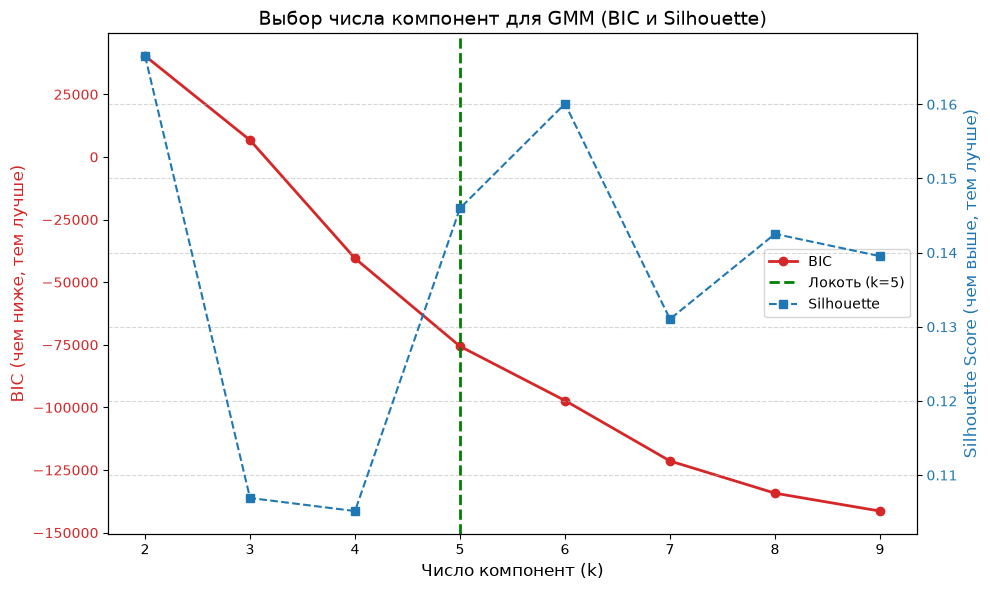

In [52]:


n_components_range = range(2, 10) 
bic_scores = []
silhouette_scores = []

print("Оценка моделей GMM:")
for n in n_components_range:
    gmm = GaussianMixture(
        n_components=n, 
        covariance_type='full',  
        random_state=42, 
        n_init=10                
    )
    gmm.fit(X_scaled)
    
    labels = gmm.predict(X_scaled)
    
    bic = gmm.bic(X_scaled)
    bic_scores.append(bic)
    
    if len(np.unique(labels)) > 1:
        sil = silhouette_score(X_scaled, labels)
    else:
        sil = -1
    silhouette_scores.append(sil)
    
    print(f"  n_components={n}: BIC={bic:.1f}, Silhouette={sil:.3f}")


fig, ax1 = plt.subplots(figsize=(10, 6))

# Метод локтя
color1 = 'tab:red'
ax1.set_xlabel('Число компонент (k)', fontsize=12)
ax1.set_ylabel('BIC (чем ниже, тем лучше)', color=color1, fontsize=12)
ax1.plot(n_components_range, bic_scores, marker='o', color=color1, label='BIC', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color1)


try:
    kl = KneeLocator(list(n_components_range), bic_scores, curve='convex', direction='decreasing')
    elbow_k = kl.elbow
    if elbow_k:
        ax1.axvline(x=elbow_k, color='green', linestyle='--', linewidth=2, label=f'Локоть (k={elbow_k})')
        print(f"\n[Метод локтя] Оптимальное число компонент: {elbow_k}")
except Exception as e:
    print("Для автоматического поиска локтя установите библиотеку: pip install kneed")

# График Silhouette 
ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('Silhouette Score (чем выше, тем лучше)', color=color2, fontsize=12)
ax2.plot(n_components_range, silhouette_scores, marker='s', color=color2, linestyle='--', label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color2)


lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')

plt.title('Выбор числа компонент для GMM (BIC и Silhouette)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
plt.show()

Для того, чтобы определить оптимальное количество кластеров, были использованы **метод силуэта и метод локтя**.

**Наилучшее значение метрики силуэта показала модель с 2 кластерами (0.167), и выбор был остановлен именно на этом варианте**

- Silhouette Score показывает, насколько объект похож на свой кластер по сравнению с соседними. Значение 0.167 при k=2 является максимальным среди всех проверенных вариантов (начиная с k=3, метрика падает). Это означает, что именно при двух кластерах точки наиболее плотно сгруппированы и наиболее далеко отстоят от соседней группы.

- Автоматический поиск «локтя» на графике BIC с помощью KneeLocator указал на k=5, это является артефактом, так как BIC не имеет истинного минимума в диапазоне от 2 до 9 компонент — он продолжает монотонно снижаться вплоть до k=9. Это свидетельствует о склонности алгоритма GMM к переобучению (выделению всё более мелких и неинтерпретируемых групп). При k=5 значение Silhouette (0.146) существенно ниже, чем при k=2, а сами кластеры становятся геометрически менее разделимыми.


Unique cluster IDs (GMM): [0 1]
Sizes (GMM): [1154 2846]


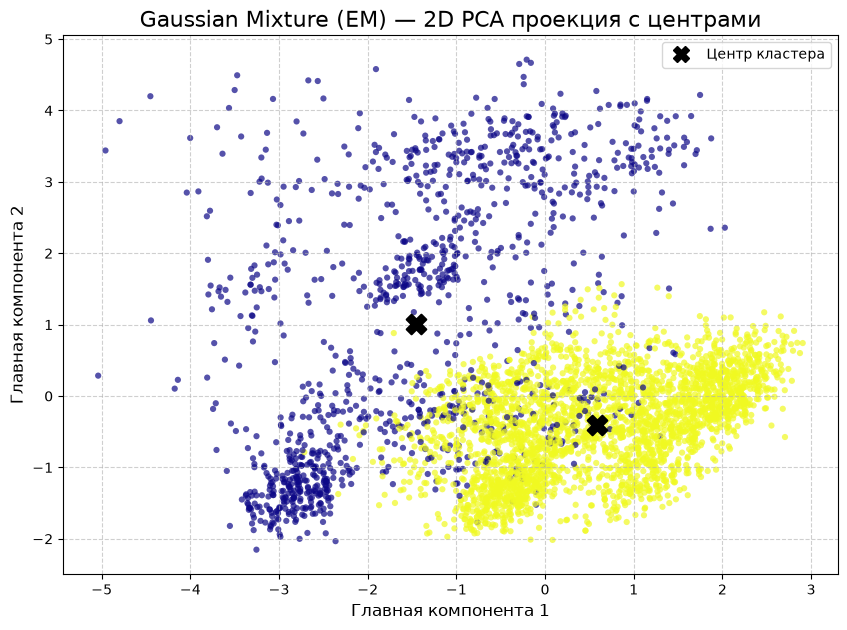

In [53]:

gmm = GaussianMixture(
    n_components=2, 
    covariance_type='full',
    random_state=42, 
    n_init=10                
)

gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)

unique, counts = np.unique(labels_gmm, return_counts=True)
print('Unique cluster IDs (GMM):', unique)
print('Sizes (GMM):', counts)


pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))


is_noise = labels_gmm == -1
is_cluster = ~is_noise

if np.any(is_noise):
    plt.scatter(
        X_pca_2d[is_noise, 0], X_pca_2d[is_noise, 1], 
        c='lightgray', s=15, alpha=0.5, 
        label='Шум (-1)', edgecolors='none'
    )


scatter = plt.scatter(
    X_pca_2d[is_cluster, 0], X_pca_2d[is_cluster, 1], 
    c=labels_gmm[is_cluster], cmap='plasma', s=20, alpha=0.7, edgecolors='none'
)


unique_clusters = [c for c in np.unique(labels_gmm) if c != -1]

for cluster_id in unique_clusters:
    cluster_mask = labels_gmm == cluster_id
    center_x = X_pca_2d[cluster_mask, 0].mean()
    center_y = X_pca_2d[cluster_mask, 1].mean()
    
 
    plt.scatter(
        center_x, center_y, 
        c='black', s=200, marker='X', edgecolors='black', linewidths=1.5,
        zorder=10
    )
    


plt.title('Gaussian Mixture (EM) — 2D PCA проекция с центрами', fontsize=16)
plt.xlabel('Главная компонента 1', fontsize=12)
plt.ylabel('Главная компонента 2', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

legend_elements = [
    Line2D([0], [0], marker='X', color='w', label='Центр кластера', 
           markerfacecolor='black', markeredgecolor='black', markersize=12)
]
if np.any(is_noise):
    legend_elements.append(Line2D([0], [0], marker='o', color='w', label='Шум', 
                                  markerfacecolor='lightgray', markersize=8))

plt.legend(handles=legend_elements, loc='best')
plt.show()

#### Построение диаграммы рассеивания в пространстве PCA

Так же как и иерархическая кластеризация, алгоритм Gaussian Mixture (EM-алгоритм) разбил данные на **2 кластера**, которые визуально различимы на проекции главных компонент. 

#### Расчет внешних и внутренних метрик качества

In [54]:

evaluate_clustering(X_scaled, labels_gmm, y, method_name="EM (GMM)")

ОЦЕНКА МЕТРИК: EM (GMM)
ВНУТРЕННИЕ МЕТРИКИ
----------------------------------------
Silhouette Score:          0.1665
Calinski-Harabasz Index:   435.67
Davies-Bouldin Index:      2.8169

РАССТОЯНИЯ МЕЖДУ КЛАСТЕРАМИ И ВНУТРИ НИХ
----------------------------------------
Расстояния между центрами кластеров (Евклид):
  Кластер 0 <-> Кластер 1: 2.6797

Среднее расстояние точек до своего центра:
  Кластер 0 (N=1154): 4.2437
  Кластер 1 (N=2846): 3.3048

ВНЕШНИЕ МЕТРИКИ
----------------------------------------
Adjusted Rand Index (ARI): -0.0396
NMI (Normalized MI):       0.0364
V-measure:                 0.0364
  ├─ Homogeneity:          0.0371 (насколько кластер чистый)
  └─ Completeness:         0.0357 (насколько класс собран)




**Внутренние метрики** (Silhouette = 0.17, Davies-Bouldin = 2.82) указывают на слабое, но всё же различимое геометрическое разделение кластеров. 

Индекс **Calinski-Harabasz (435.67)** является достаточно высоким для данной размерности пространства, что говорит о превышении межкластерного разброса над внутрикластерным (центры групп находятся далеко друг от друга). 

Значение **Silhouette (0.17)** подтверждает, что границы между группами размыты и точки в некоторой степени пересекаются.

 Индекс **Davies-Bouldin (2.82)** показывает, что внутрикластерный разброс сопоставим с расстоянием между центрами.

**Расстояние между центрами кластеров** (2.68) меньше **среднего расстояния точек до своего центра** в Кластере 0 (4.24), что указывает на частичное перекрытие групп в многомерном пространстве. Кластер 0 (N=1154) является заметно более неоднородным, тогда как Кластер 1 (N=2846) более компактен (3.30) и близок по разбросу к межцентровому расстоянию. Это подтверждает, что найденная структура не является идеально разделённой геометрически, но разница в плотности групп указывает на то, что алгоритм уловил реальные различия в данных.

 **Внешние метрики** (ARI = -0.04, NMI = 0.04) показывают полное отсутствие согласованности между найденными кластерами и исходными классами. Это означает, что алгоритм разделил студентов по другим признакам

#### Анализ центров кластеров и интерпретация выделенных групп

In [55]:
df_original = df_encoded.copy()


df_original['Cluster'] = labels_gmm


num_cols = df_original.select_dtypes(include=['number']).columns.drop('Cluster', errors='ignore').tolist()


raw_means = df_original.groupby('Cluster')[num_cols].mean()

print("СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ (В ИСХОДНЫХ ЕДИНИЦАХ):")
display(raw_means.T.round(2))

СРЕДНИЕ ЗНАЧЕНИЯ ПРИЗНАКОВ ПО КЛАСТЕРАМ (В ИСХОДНЫХ ЕДИНИЦАХ):


Cluster,0,1
Age,23.28,22.33
Current_semester,5.84,5.11
CGPA,3.43,3.40
Cost_without_study,14096.51,9445.47
Gender_Male,0.26,0.52
Family_background_Middle class,0.42,0.67
Family_background_Rich class,0.50,0.00
Relationship_status_Single,0.34,0.75
Marital_status_Separated,0.06,0.00
Marital_status_Unmarried,0.39,1.00



Для того чтобы понять, почему внешние метрики показывают такой низкий результат и по каким признакам разбиты данные, были расчитаны **центры кластеров**.

**Кластер 1** объединил студентов из семей среднего класса (средние расходы Cost_without_study — 9 445, доля Rich class равна 0)

**Кластер 0** представляет собой группу студентов из обеспеченных семей (средние расходы — 14 096, доля Rich class достигает 0.5).

 При этом центры кластеров практически не отличаются по возрасту, успеваемости  и состоянию здоровья.

**Алгоритм разделил студентов по уровню достатка, а не по наличию депрессии.**




### Сравнение результатов, полученных разными методами

In [56]:
methods = {
    'Hierarchical (Ward)': labels_ward,
    'EM (GMM)': labels_gmm,

}

metrics_list = []

for name, labels in methods.items():
    unique, counts = np.unique(labels, return_counts=True)
    row = {
        'Method': name,
        'Silhouette (↑)': silhouette_score(X_scaled, labels),
        'Calinski-Harabasz (↑)': calinski_harabasz_score(X_scaled, labels),
        'Davies-Bouldin (↓)': davies_bouldin_score(X_scaled, labels),
        'ARI (↑)': adjusted_rand_score(y, labels),
        'NMI (↑)': normalized_mutual_info_score(y, labels),
        'V-measure (↑)': v_measure_score(y, labels),
        'Sizes:': counts
        
        }
    metrics_list.append(row)


df_metrics = pd.DataFrame(metrics_list).set_index('Method')
df_metrics = df_metrics.round(4)

print("СРАВНИТЕЛЬНАЯ ТАБЛИЦА МЕТРИК КАЧЕСТВА КЛАСТЕРИЗАЦИИ")
print("="*60)
display(df_metrics)

print("\n" + "="*60)
print("СРАВНЕНИЕ МЕТОДОВ МЕЖДУ СОБОЙ (Ward vs GMM)")
print("="*60)


ari_between_methods = adjusted_rand_score(labels_ward, labels_gmm)
nmi_between_methods = normalized_mutual_info_score(labels_ward, labels_gmm)

print(f"ARI между Ward и GMM:  {ari_between_methods:.4f}")
print(f"NMI между Ward и GMM:  {nmi_between_methods:.4f}")


СРАВНИТЕЛЬНАЯ ТАБЛИЦА МЕТРИК КАЧЕСТВА КЛАСТЕРИЗАЦИИ


,Silhouette (↑),Calinski-Harabasz (↑),Davies-Bouldin (↓),ARI (↑),NMI (↑),V-measure (↑),Sizes:
Method,,,,,,,
Hierarchical (Ward),0.1934,426.9016,1.9590,-0.0810,0.0533,0.0533,"[549, 427, 3024]"
EM (GMM),0.1665,435.6728,2.8169,-0.0396,0.0364,0.0364,"[1154, 2846]"



СРАВНЕНИЕ МЕТОДОВ МЕЖДУ СОБОЙ (Ward vs GMM)
ARI между Ward и GMM:  0.7626
NMI между Ward и GMM:  0.6521


Оба алгоритма провели успешное разбиение данных, но Ward выделил 3 кластера, а GMM — 2 кластера.

Анализ центров показал, что оба метода выявили разбиение по уровню достатка: GMM четко разделил студентов на группу из обеспеченных семей с высокими расходами (N=1154) и группу среднего класса (N=2846). Ward, в свою очередь, выделил «богатых» (N=549), старших студентов  (N=427) и молодых студентов из среднего класса (N=3024).

Внутренние метрики показывают, что Ward справился с геометрическим разделением лучше: у него выше Silhouette Score (0.1934 против 0.1665 у GMM) и значительно лучше индекс Davies-Bouldin (1.96 против 2.81). Индекс Calinski-Harabasz оказался практически одинаковым (426.9 у Ward и 435.7 у GMM), что означает сопоставимое отношение межкластерного разброса к внутрикластерному. 

Более высокое значение Davies-Bouldin и меньший Silhouette у кластеров GMM указывают на то, что **Ward нашел более компактные и хорошо отделимые группы**.

Исходно заданные классы (наличие депрессии) не совпадают с найденными кластерами. Об этом свидетельствуют крайне низкие значения внешних метрик (ARI ≈ -0.04–(-0.08), NMI ≈ 0.04–0.05) для обоих методов. Алгоритмы разделили студентов по социально-экономическим и демографическим признакам, а не по психологическому состоянию.

Сравнение методов между собой показало высокое значение ARI (0.7626) и NMI (0.6521). Это означает, что, несмотря на разные математические подходы и разное число кластеров (Ward выделил 3 группы, GMM — 2), оба алгоритма уловили одну и ту же общую структуру. То, что 3-кластерное разбиение Ward на 76% совпадает с 2-кластерным разбиением GMM, подтверждает объективность и устойчивость выявленного разделения данных по уровню достатка.

### Исследование влияния параметров EM-алгоритма на качество кластеризации.

Главным параметром EM-алгоритма является количество кластеров. Переберем значения от 1 до 10 и вычислим метрики, чтобы исследовать влияние параметра на качество кластеризации.

Исследование влияния числа компонент (k) на GMM:

k =  2 | BIC =  40356.0 | AIC =  38650.3 | Sil = 0.167 | CH =  435.7 | DB = 2.817
k =  3 | BIC =   6714.3 | AIC =   4152.6 | Sil = 0.107 | CH =  391.2 | DB = 2.212
k =  4 | BIC = -40496.3 | AIC = -43914.0 | Sil = 0.105 | CH =  426.6 | DB = 2.313
k =  5 | BIC = -75597.1 | AIC = -79870.8 | Sil = 0.146 | CH =  450.5 | DB = 1.946
k =  6 | BIC = -97252.1 | AIC = -102381.7 | Sil = 0.160 | CH =  450.4 | DB = 1.776
k =  7 | BIC = -121375.2 | AIC = -127360.9 | Sil = 0.131 | CH =  436.5 | DB = 1.853
k =  8 | BIC = -134232.4 | AIC = -141074.0 | Sil = 0.143 | CH =  416.5 | DB = 1.945
k =  9 | BIC = -141372.7 | AIC = -149070.3 | Sil = 0.140 | CH =  378.0 | DB = 2.033
k = 10 | BIC = -145519.3 | AIC = -154073.0 | Sil = 0.127 | CH =  360.8 | DB = 1.939


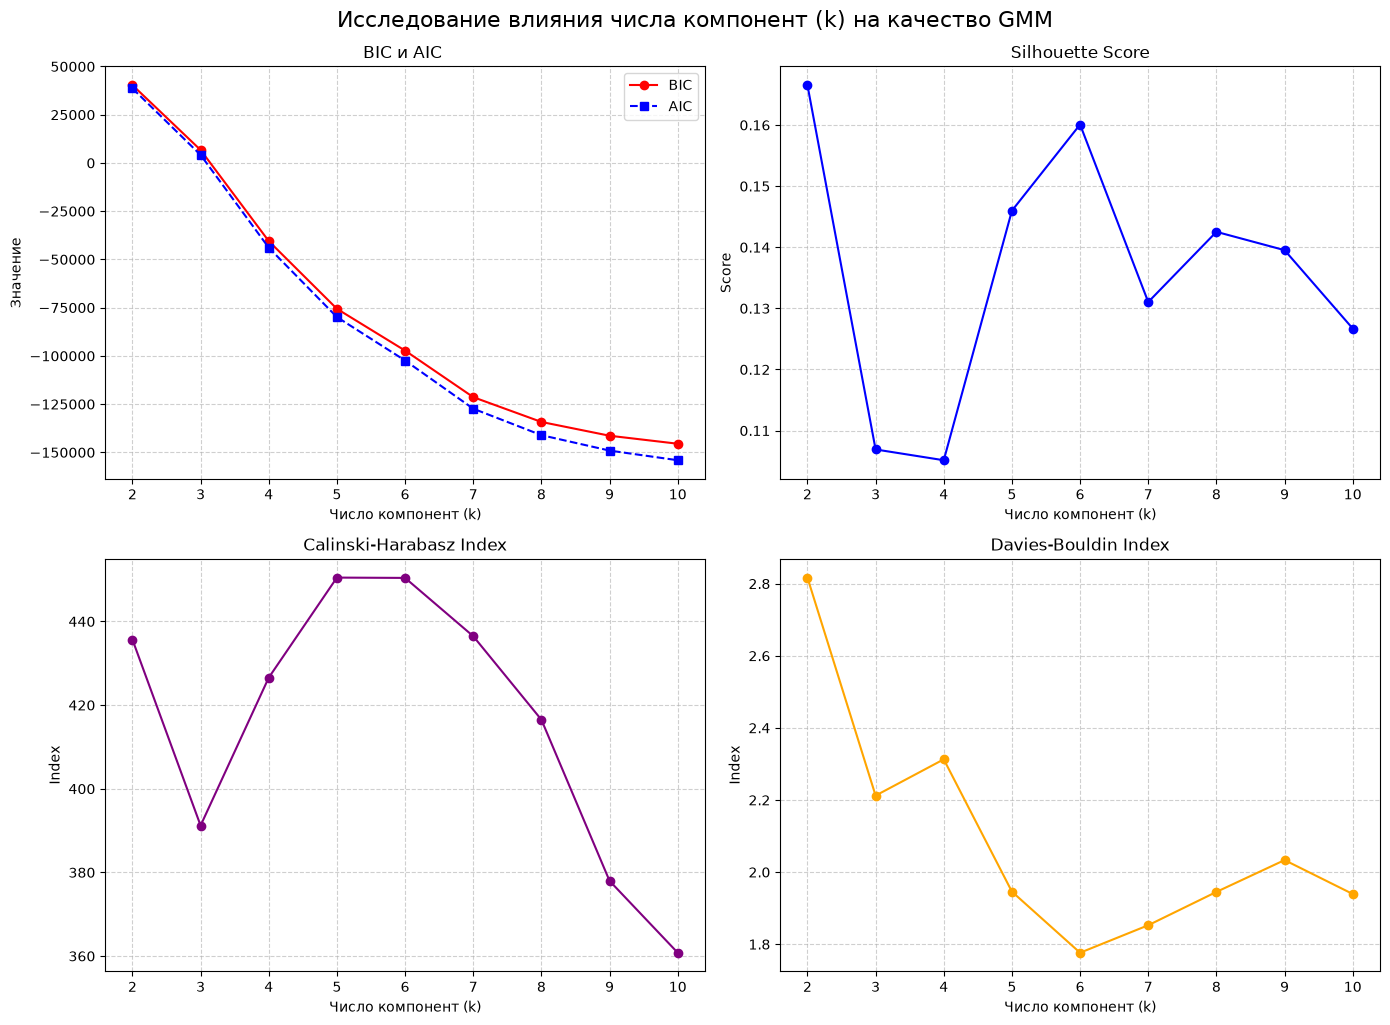

In [57]:

results = {
    'n_components': [],
    'BIC': [],
    'AIC': [],
    'Silhouette': [],
    'Calinski-Harabasz': [],
    'Davies-Bouldin': []
}

n_components_range = range(2, 11)

print("Исследование влияния числа компонент (k) на GMM:\n")

for n in n_components_range:
    gmm = GaussianMixture(
        n_components=n, 
        covariance_type='full',  
        random_state=42, 
        n_init=10                 
    )
    gmm.fit(X_scaled)
    
    labels = gmm.predict(X_scaled)
    
    bic = gmm.bic(X_scaled)
    aic = gmm.aic(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    
  
    results['n_components'].append(n)
    results['BIC'].append(bic)
    results['AIC'].append(aic)
    results['Silhouette'].append(sil)
    results['Calinski-Harabasz'].append(ch)
    results['Davies-Bouldin'].append(db)
    
    print(f"k = {n:>2} | BIC = {bic:>8.1f} | AIC = {aic:>8.1f} | "
          f"Sil = {sil:.3f} | CH = {ch:>6.1f} | DB = {db:.3f}")


df_results = pd.DataFrame(results)


fig, axes = plt.subplots(2, 2, figsize=(14, 10))


axes[0, 0].plot(df_results['n_components'], df_results['BIC'], marker='o', label='BIC', color='red')
axes[0, 0].plot(df_results['n_components'], df_results['AIC'], marker='s', label='AIC', color='blue', linestyle='--')
axes[0, 0].set_title('BIC и AIC ', fontsize=12)
axes[0, 0].set_xlabel('Число компонент (k)')
axes[0, 0].set_ylabel('Значение')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

axes[0, 1].plot(df_results['n_components'], df_results['Silhouette'], marker='o', color='blue')
axes[0, 1].set_title('Silhouette Score', fontsize=12)
axes[0, 1].set_xlabel('Число компонент (k)')
axes[0, 1].set_ylabel('Score')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)


axes[1, 0].plot(df_results['n_components'], df_results['Calinski-Harabasz'], marker='o', color='purple')
axes[1, 0].set_title('Calinski-Harabasz Index', fontsize=12)
axes[1, 0].set_xlabel('Число компонент (k)')
axes[1, 0].set_ylabel('Index')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)


axes[1, 1].plot(df_results['n_components'], df_results['Davies-Bouldin'], marker='o', color='orange')
axes[1, 1].set_title('Davies-Bouldin Index', fontsize=12)
axes[1, 1].set_xlabel('Число компонент (k)')
axes[1, 1].set_ylabel('Index')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.suptitle('Исследование влияния числа компонент (k) на качество GMM', fontsize=16, y=1.02)
plt.show()

**Анализ BIC и AIC** показал, что эти информационные критерии продолжают снижаться вплоть до k=10, не образуя чёткого минимума («локтя»), что свидетельствует о склонности алгоритма к переобучению при увеличении числа компонент.

 Геометрические метрики дают противоречивые результаты. Silhouette Score достигает абсолютного максимума при k=2 (≈0.165), что указывает на наиболее чёткое разделение точек. Индекс Davies-Bouldin при k=2 максимален (≈2.8 — худшее значение), а своего минимума (лучшее значение ≈1.78) достигает при k=6. Индекс Calinski-Harabasz также имеет максимум в районе k=5–6 (≈450), а при k=2 он ниже (≈435).

Несмотря на то, что BIC/AIC, а также метрики компактности (Davies-Bouldin и Calinski-Harabasz) склоняются к увеличению числа кластеров, это является следствием переобучения модели: алгоритм начинает дробить единое плотное облако на мелкие искусственные группы. Silhouette Score указывает на k=2 как на оптимальное разбиение, отражающее естественный разлом в данных.

С точки зрения интерпретируемости и устойчивости именно k=2 является обоснованным выбором, подтверждающим результаты иерархической кластеризации. Дальнейшее дробление не улучшает реальное качество разделения, а лишь подстраивается под шум.

## Вывод

- Иерархическая кластеризация (Ward) была выбрана за способность работать с вытянутыми и несбалансированными структурами без априорного задания числа кластеров (выбор k по дендрограмме), а EM-алгоритм (GMM) — за возможность моделировать кластеры в виде эллипсов разной плотности.

- Иерархическая кластеризация (Ward) разделила данные на 3 кластера, а EM-алгоритм (GMM) — на 2 кластера. Анализ центров показал, что в обоих случаях разбиение произошло по уровню достатка семьи и демографическим признакам (возраст, семейное положение), а не по наличию депрессии. GMM чётко отделил «богатых» от «среднего класса», а Ward дополнительно выделил подгруппу старших студентов.

- Внутренние метрики продемонстрировали слабое, но различимое геометрическое разделение (Silhouette ≈ 0.17–0.19). При этом Ward справился с разделением лучше: у него выше Silhouette (0.193 против 0.166) и значительно лучше индекс Davies-Bouldin (1.96 против 2.81 у GMM), что говорит о большей компактности и изолированности кластеров. По индексу Calinski-Harabasz методы оказались практически равны (426.9 против 435.7 в пользу GMM). Внешние метрики оказались близки к нулю (ARI ≈ -0.04–(-0.08), NMI ≈ 0.04–0.05), подтвердив отсутствие связи найденных кластеров с целевой переменной Depression.

- Сравнение методов между собой показало высокое значение ARI (0.76) и NMI (0.65), что свидетельствует о том, что, несмотря на разное число кластеров (3 у Ward и 2 у GMM), оба алгоритма уловили одну и ту же объективную структуру данных (разделение по достатку).

- Исследование числа компонент GMM показало, что BIC и AIC продолжают снижаться вплоть до k=10. Метрики компактности (Davies-Bouldin и Calinski-Harabasz) склоняются к увеличению числа кластеров (вплоть до k=5–6), это является следствием переобучения модели. Silhouette, достигает максимума именно при k=2, что подтверждает оптимальность двухкластерного разбиения.